<a href="https://colab.research.google.com/github/lnrdmnc/Quantum-Enhanced-Detection-Mechanisms-for-Mobile-Network-Security/blob/main/QA_Wired_from_Variational_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Wiring Quantum Annealing QUBOs to Variational Energies (VQE/QAOA)

This notebook trains compact **VQE**/**QAOA** heads for two RF security tasks and constructs **QUBOs** whose costs are the **variational energies**:

- **PSD anomaly (benign/fake/tone)** → one-hot QUBO over classes with costs $E_c(x)=\langle H_c\rangle$.
- **RACH root selection** → one-hot QUBO over ZC roots with costs $E^{(c)}_{\text{pos}}(x)$ from a small QAOA/VQE bank.

We also export Ocean-compatible QUBO JSONs.

In [11]:
%pip install pennylane pennylane-lightning[qubit]
import pennylane as qml
from pennylane import numpy as pnp
import numpy as np, numpy.fft as fft
import matplotlib.pyplot as plt
import json
print('PennyLane', qml.__version__)

import os

psd_qubo_path = '/mnt/data/psd_variational_qubo.json'
os.makedirs(os.path.dirname(psd_qubo_path), exist_ok=True)

PennyLane 0.42.3


## RF helpers and features

In [12]:
def gen_ofdm_like(N=1024, subcarriers=(60,120,200), amps=(1.0,0.8,0.6), noise=0.05):
    t=np.arange(N); x=np.zeros(N,dtype=complex)
    for f,a in zip(subcarriers,amps): x += a*np.exp(1j*2*np.pi*f*t/N)
    x += noise*(np.random.randn(N)+1j*np.random.randn(N)); return x
def shift_sync(x, shift_bins=6): X=fft.fft(x); X=np.roll(X, shift_bins); return fft.ifft(X)
def add_tone(x, bin_idx=150, amp=3.0): N=len(x); n=np.arange(N); return x + amp*np.exp(1j*2*np.pi*bin_idx*n/N)
def psd_feature(x, n_bins=16): P=np.abs(fft.fft(x))**2; k=len(P)//n_bins; P=P[:k*n_bins].reshape(n_bins,k).mean(axis=1); return (P/(P.max()+1e-12)).astype(float)
def zadoff_chu(u,Nzc): n=np.arange(Nzc); return np.exp(-1j*np.pi*u*n*(n+1)/Nzc)
def rach_burst(zc, delay=12, snr_db=12.0): N=len(zc); x=np.zeros(N,dtype=complex); x[delay:]=zc[:N-delay]; snr=10**(snr_db/10); p=np.mean(np.abs(x)**2)+1e-12; npwr=p/snr; noise=np.sqrt(npwr/2)*(np.random.randn(N)+1j*np.random.randn(N)); return x+noise
def corr_feature_refnorm(rx, ref, n_bins=16, ref_scale=None):
  r=np.correlate(rx,ref,mode='same'); c=np.abs(r);
  if ref_scale is None: rr=np.correlate(ref,ref,mode='same'); ref_scale=float(np.max(np.abs(rr)))
  c=c/(ref_scale+1e-12); k=len(c)//n_bins; return c[:k*n_bins].reshape(n_bins,k).mean(axis=1).astype(float)

## Ising heads and circuits (VQE and QAOA)

In [13]:
def build_ising_H_from_stats(mean_vec, cov_mat, wires, kappa=1.0):
    H = 0
    mu = mean_vec - mean_vec.mean()
    for wi, a in zip(wires, mu): H = H + float(a) * qml.PauliZ(wi)
    for i in range(len(wires)-1):
        J = kappa * float(cov_mat[i, i+1])
        if abs(J)>1e-12: H = H + J * (qml.PauliZ(wires[i]) @ qml.PauliZ(wires[i+1]))
    return H
def angle_embed(x, wires): qml.AngleEmbedding(x, wires=wires, rotation='Y')
def ansatz_vqe(theta, L, wires):
    n=len(wires); idx=0
    for _ in range(L):
        for w in wires: qml.RZ(theta[idx], wires=w); idx+=1
        for w in wires: qml.RX(theta[idx], wires=w); idx+=1
        for i in range(n): qml.CNOT(wires=[wires[i], wires[(i+1)%n]])
        for i in range(n): qml.IsingZZ(0.25, wires=[wires[i], wires[(i+1)%n]])
def qaoa_block(gammas, betas, H, wires):
    mixer_h = qml.qaoa.x_mixer(wires)
    for g,b in zip(gammas,betas):
        qml.qaoa.cost_layer(g, H)
        qml.qaoa.mixer_layer(b, mixer_h)

## PSD: train small VQE/QAOA heads and build QUBOs

In [14]:
np.random.seed(0)
B=16; wires=list(range(B))
def build_psd_dataset(B=16, N=1024, n=120):
    Xb=np.stack([psd_feature(gen_ofdm_like(N), B) for _ in range(n)],axis=0)
    Xf=np.stack([psd_feature(shift_sync(gen_ofdm_like(N),6), B) for _ in range(n)],axis=0)
    Xt=np.stack([psd_feature(add_tone(gen_ofdm_like(N),150,3.0), B) for _ in range(n)],axis=0)
    return Xb, Xf, Xt
Xb, Xf, Xt = build_psd_dataset(B=B, n=120)
mu_b, mu_f, mu_t = Xb.mean(0), Xf.mean(0), Xt.mean(0)
Cb, Cf, Ct = np.cov(Xb.T), np.cov(Xf.T), np.cov(Xt.T)
H_b = build_ising_H_from_stats(mu_b,Cb,wires); H_f = build_ising_H_from_stats(mu_f,Cf,wires); H_t = build_ising_H_from_stats(mu_t,Ct,wires)

# VQE head (shared for classes)
dev_vqe = qml.device('default.qubit', wires=B)
@qml.qnode(dev_vqe)
def E_vqe(th, x, H): angle_embed(x,wires); ansatz_vqe(th,2,wires); return qml.expval(H)
def loss_vqe(th):
    # Contrastive: benign vs fake
    Eb = pnp.mean(pnp.stack([E_vqe(th, x, H_b) for x in Xb[:32]]))
    Ef = pnp.mean(pnp.stack([E_vqe(th, x, H_f) for x in Xf[:32]]))
    return Eb + qml.math.maximum(0.0, 0.15 - (Ef - Eb))
th = pnp.random.uniform(-0.1,0.1, size=2*B*2)
opt = qml.AdamOptimizer(0.05)
for s in range(40): th,_ = opt.step_and_cost(loss_vqe, th)

# QAOA head
dev_q = qml.device('default.qubit', wires=B); p=2
@qml.qnode(dev_q)
def E_qaoa(pr, x, H):
    gam=pr[:p]; bet=pr[p:2*p]
    angle_embed(x,wires); qaoa_block(gam,bet,H,wires); return qml.expval(H)
def loss_qaoa(pr):
    Eb = pnp.mean(pnp.stack([E_qaoa(pr, x, H_b) for x in Xb[:32]]))
    Ef = pnp.mean(pnp.stack([E_qaoa(pr, x, H_f) for x in Xf[:32]]))
    return Eb + qml.math.maximum(0.0, 0.15 - (Ef - Eb))
pr = pnp.random.uniform(-0.1,0.1, size=2*p)
optq = qml.AdamOptimizer(0.05)
for s in range(40): pr,_ = optq.step_and_cost(loss_qaoa, pr)

# Build PSD one-hot QUBO from QAOA energies and evaluate
def build_onehot_qubo(costs, A=5.0):
    labs=list(costs.keys()); n=len(labs); Q=np.zeros((n,n)); c=np.zeros(n)
    for i,l in enumerate(labs): c[i]=float(costs[l])-A
    for i in range(n):
        for j in range(i+1,n): Q[i,j]+=2*A
    return labs,Q,c
def solve_onehot(Q,c):
    n=len(c); bestE=1e9; best=None
    for i in range(n): z=np.zeros(n); z[i]=1; E=float(z@Q@z + c@z);
    if E<bestE: bestE=E; best=z
    return best,bestE

Xb_val, Xf_val = Xb[80:120], Xf[80:120]
labels_true = np.array(['benign']*len(Xb_val) + ['fake']*len(Xf_val))
X_val = np.concatenate([Xb_val, Xf_val],axis=0)
preds=[]
for x in X_val:
    costs={'benign': float(E_qaoa(pr,x,H_b)), 'fake': float(E_qaoa(pr,x,H_f)), 'tone': float(E_qaoa(pr,x,H_t))}
    labs,Q,c = build_onehot_qubo(costs, A=5.0)
    z,_ = solve_onehot(Q,c)
    pred = labs[int(np.argmax(z))]
    if pred=='tone': pred='fake'
    preds.append(pred)
acc = (labels_true==np.array(preds)).mean(); print({'PSD_QUBO_variational_accuracy': float(acc)})

# Export one example PSD QUBO
labs,Q,c = build_onehot_qubo({'benign': float(E_qaoa(pr,X_val[0],H_b)), 'fake': float(E_qaoa(pr,X_val[0],H_f)), 'tone': float(E_qaoa(pr,X_val[0],H_t))}, A=5.0)
psd_qubo_path = '/mnt/data/psd_variational_qubo.json'
obj={'type':'QUBO','Q':{f'{i},{j}': float(Q[i,j]) for i in range(len(c)) for j in range(i,len(c)) if (i==j and abs(c[i])>1e-12) or (i<j and abs(Q[i,j])>1e-12)}, 'labels': {'classes': labs}}
with open(psd_qubo_path,'w') as f: json.dump(obj,f,indent=2)
print('Exported PSD QUBO ->', psd_qubo_path)

{'PSD_QUBO_variational_accuracy': 0.5}
Exported PSD QUBO -> /mnt/data/psd_variational_qubo.json


## RACH: small QAOA/VQE root bank and root-selection QUBO

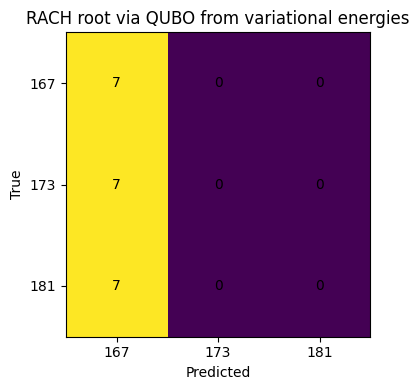

{'RACH_QUBO_variational_root_acc': 0.3333333333333333}
Exported RACH root QUBO -> /mnt/data/rach_variational_root_qubo.json


In [15]:
np.random.seed(1)
B=16; wires=list(range(B))
roots=[167,173,181]
zc={u: zadoff_chu(u,839) for u in roots}
ref_scale={u: float(np.max(np.abs(np.correlate(zc[u],zc[u],mode='same')))) for u in roots}
def build_rach_bank(roots, n_pos=14, n_neg=30):
    ds={}
    for u in roots:
        pos=np.stack([corr_feature_refnorm(rach_burst(zc[u], 12+d), zc[u], n_bins=B, ref_scale=ref_scale[u]) for d in range(-3,4)],axis=0)
        ds[u]={'pos': pos}
    # shared negatives
    neg=np.stack([corr_feature_refnorm(rach_burst(zc[np.random.choice(roots)], np.random.randint(40,120)), zc[np.random.choice(roots)], n_bins=B, ref_scale=ref_scale[roots[0]]) for _ in range(n_neg)],axis=0)
    return ds, neg
ds_mr, shared_neg = build_rach_bank(roots)
mu_pos={u: ds_mr[u]['pos'].mean(0) for u in roots}
C_pos={u: np.cov(ds_mr[u]['pos'].T) for u in roots}
mu_neg = shared_neg.mean(0); C_neg = np.cov(shared_neg.T)
Hpos_bank={u: build_ising_H_from_stats(mu_pos[u], C_pos[u], wires) for u in roots}
Hneg_bank = build_ising_H_from_stats(mu_neg, C_neg, wires)

# QAOA bank: shared params across roots
pB=2; dev_bank = qml.device('default.qubit', wires=B)
@qml.qnode(dev_bank)
def E_bank_qaoa(params, x, H):
    gam=params[:pB]; bet=params[pB:2*pB]
    angle_embed(x,wires); qaoa_block(gam,bet,H,wires); return qml.expval(H)
def loss_bank(params, m=0.08):
    # margin between shared negative and average positive across roots
    Ep=[]
    for u in roots:
        for x in ds_mr[u]['pos'][:4]: Ep.append(E_bank_qaoa(params, x, Hpos_bank[u]))
    Ep=pnp.mean(pnp.stack(Ep))
    En=pnp.mean(pnp.stack([E_bank_qaoa(params, x, Hneg_bank) for x in shared_neg[:8]]))
    return Ep + qml.math.maximum(0.0, m - (En - Ep))
params_bank = pnp.random.uniform(-0.1,0.1, size=2*pB); optb = qml.AdamOptimizer(0.05)
for s in range(60): params_bank,_ = optb.step_and_cost(loss_bank, params_bank)

def root_costs_from_variational(x):
    return {str(u): float(E_bank_qaoa(params_bank, x, Hpos_bank[u])) for u in roots}
def build_onehot_qubo(costs, A=5.0):
    labs=list(costs.keys()); n=len(labs); Q=np.zeros((n,n)); c=np.zeros(n)
    for i,l in enumerate(labs): c[i]=float(costs[l])-A
    for i in range(n):
        for j in range(i+1,n): Q[i,j]+=2*A
    return labs,Q,c

def solve_onehot(Q, c):
    n = len(c)
    bestE = float("inf")
    best = None
    for i in range(n):
        z = np.zeros(n)
        z[i] = 1
        E = float(z @ Q @ z + c @ z)
        if E < bestE:
            bestE = E
            best = z
    return best, bestE

# Confusion matrix over positives
roots_list = list(roots)
C = np.zeros((len(roots_list), len(roots_list)), dtype=int)
for i,u_true in enumerate(roots_list):
    for x in ds_mr[u_true]['pos']:
        costs = root_costs_from_variational(x)
        labs,Q,c = build_onehot_qubo(costs, A=5.0)
        z,_ = solve_onehot(Q,c)
        u_pred = int(labs[int(np.argmax(z))])
        C[i, roots_list.index(u_pred)] += 1
plt.figure(figsize=(5,4))
plt.imshow(C, interpolation='nearest'); plt.title('RACH root via QUBO from variational energies')
plt.xlabel('Predicted'); plt.ylabel('True')
plt.xticks(range(len(roots_list)), roots_list); plt.yticks(range(len(roots_list)), roots_list)
for i in range(C.shape[0]):
    for j in range(C.shape[1]): plt.text(j,i,str(C[i,j]),ha='center',va='center')
plt.tight_layout(); plt.show()
acc = np.trace(C)/C.sum(); print({'RACH_QUBO_variational_root_acc': float(acc)})

# Export one example root QUBO
x_example = ds_mr[roots_list[0]]['pos'][0]
labs,Q,c = build_onehot_qubo(root_costs_from_variational(x_example), A=5.0)
rach_qubo_path = '/mnt/data/rach_variational_root_qubo.json'
obj={'type':'QUBO','Q':{f'{i},{j}': float(Q[i,j]) for i in range(len(c)) for j in range(i,len(c)) if (i==j and abs(c[i])>1e-12) or (i<j and abs(Q[i,j])>1e-12)}, 'labels': {'roots': labs}}
with open(rach_qubo_path,'w') as f: json.dump(obj,f,indent=2)
print('Exported RACH root QUBO ->', rach_qubo_path)

## RACH Root + Delay QUBO from Variational Energies
We extend the root-only selection to a **root+delay** joint decision.
For each candidate root $u$ and delay $d$, we compute a feature vector tied to that hypothesis and evaluate
the **positive head energy** $E_{u,d}(x)=\langle H^{(u)}_{\text{pos}}\rangle$ using the trained bank.
We then minimize a one-hot QUBO with variables $r_u\in\{0,1\}$ (root) and $d_\ell\in\{0,1\}$ (delay bin):
$$\min\; \sum_{u,\ell} E_{u,\ell}(x)\, r_u d_\ell + A(\sum_u r_u -1)^2 + B(\sum_\ell d_\ell -1)^2.$$

In [16]:
import numpy as _np
import json
import matplotlib.pyplot as plt

# Candidate delays around nominal preamble start
delays = list(range(8,17))  # 8..16 inclusive

def shift_time(rx, shift):
    # circular shift by -shift so a hypothesized delay aligns to 0
    return _np.roll(rx, -int(shift))

def rach_feature_for_hypothesis(rx, root_u, delay_bin, n_bins=16):
    # align rx by hypothesized delay, then compute reference-normalized correlation features
    rx_h = shift_time(rx, delay_bin)
    return corr_feature_refnorm(rx_h, zc[root_u], n_bins=n_bins, ref_scale=ref_scale[root_u])

def E_table_root_delay(rx, prefer='qaoa'):
    # Build cost matrix E_{u,l} from variational energies for each root u and delay l
    K, L = len(roots), len(delays)
    E = _np.zeros((K,L))
    for i,u in enumerate(roots):
        for j,l in enumerate(delays):
            x_feat = rach_feature_for_hypothesis(rx, u, l, n_bins=len(wires))
            if prefer=='qaoa':
                E[i,j] = float(E_bank_qaoa(params_bank, x_feat, Hpos_bank[u]))
            else:
                # fallback to VQE if available
                E[i,j] = float(E_vqe(th, x_feat, Hpos_bank[u]))
    return E

def build_root_delay_qubo(E, A=10.0, B=10.0):
    # E shape KxL; variables are first K roots then L delays
    K,L = E.shape
    n = K+L
    Q = _np.zeros((n,n)); c = _np.zeros(n)
    # bilinear data terms: sum E_{k,l} r_k d_l, map to upper triangle
    for k in range(K):
        for l in range(L):
            Q[k, K+l] += 0.5*E[k,l]
    # root one-hot penalties
    for k in range(K): c[k] += -A
    for k1 in range(K):
        for k2 in range(k1+1,K): Q[k1,k2] += 2*A
    # delay one-hot penalties
    for l in range(L): c[K+l] += -B
    for l1 in range(L):
        for l2 in range(l1+1,L): Q[K+l1, K+l2] += 2*B
    return Q, c

def solve_root_delay_bruteforce(Q, c):
    # enforce one-hot by construction for speed
    K = len(roots); L = len(delays); n=K+L
    bestE = 1e9; best = None
    for ki in range(K):
        for lj in range(L):
            z = _np.zeros(n)
            z[ki]=1; z[K+lj]=1
            E = float(z@Q@z + c@z)
            if E < bestE:
                bestE = E; best = (ki, lj)
    return best, bestE

# --- Build a small evaluation set of received signals with known (root, delay) ---
def build_rx_eval(roots, n_per_root=10):
    samples = []
    for u in roots:
        for _ in range(n_per_root):
            d_true = int(_np.random.choice(delays))
            rx = rach_burst(zc[u], delay=d_true, snr_db=12.0)
            samples.append({'u_true': u, 'd_true': d_true, 'rx': rx})
    return samples

eval_set = build_rx_eval(roots, n_per_root=12)

# --- Evaluate ---
acc_root = 0; acc_delay = 0; abs_errs = []
for item in eval_set:
    E = E_table_root_delay(item['rx'], prefer='qaoa')
    Q,c = build_root_delay_qubo(E, A=10.0, B=10.0)
    (ki, lj), _ = solve_root_delay_bruteforce(Q,c)
    u_hat = roots[ki]; d_hat = delays[lj]
    acc_root += int(u_hat == item['u_true'])
    acc_delay += int(d_hat == item['d_true'])
    abs_errs.append(abs(d_hat - item['d_true']))

N = len(eval_set)
print({'root_acc': acc_root/N, 'delay_acc': acc_delay/N, 'mean_abs_delay_error': float(_np.mean(abs_errs))})

# --- Export one example QUBO ---
E_ex = E_table_root_delay(eval_set[0]['rx'], prefer='qaoa')
Q_ex, c_ex = build_root_delay_qubo(E_ex, A=10.0, B=10.0)
export_path = '/mnt/data/rach_root_delay_variational_qubo.json'
Q_upper = {}
n = len(c_ex)
for i in range(n):
    if abs(c_ex[i])>1e-12: Q_upper[(i,i)] = float(c_ex[i])
    for j in range(i+1,n):
        if abs(Q_ex[i,j])>1e-12: Q_upper[(i,j)] = float(Q_ex[i,j])
obj = {'type':'QUBO', 'Q': {f'{i},{j}': v for (i,j),v in Q_upper.items()}, 'labels': {'roots': [int(u) for u in roots], 'delays': [int(d) for d in delays]}}
with open(export_path,'w') as f: json.dump(obj,f,indent=2)
print('Exported root+delay QUBO ->', export_path)

{'root_acc': 0.3333333333333333, 'delay_acc': 0.1111111111111111, 'mean_abs_delay_error': 3.5555555555555554}
Exported root+delay QUBO -> /mnt/data/rach_root_delay_variational_qubo.json


## Local Sampling with Ocean's `neal` (Optional)
This section loads the exported QUBOs and samples them locally with Ocean's **SimulatedAnnealingSampler**.
If `dimod`/`neal` are not installed, the cell will print a helpful message and skip.

In [17]:
import json, os
import numpy as _np
import matplotlib.pyplot as plt

def load_qubo_from_json(path):
    with open(path,'r') as f:
        obj = json.load(f)
    Q = {}
    for k,v in obj['Q'].items():
        i,j = map(int, k.split(','))
        Q[(i,j)] = float(v)
    labels = obj.get('labels', {})
    return Q, labels

def sample_with_neal(Q, num_reads=5000, beta_range=None):
    try:
        import dimod
        import neal
    except Exception as e:
        print('Ocean dimod/neal not available, skipping local sampling. Error:', e)
        return None
    bqm = dimod.BinaryQuadraticModel.from_qubo(Q)
    sampler = neal.SimulatedAnnealingSampler()
    kwargs = {'num_reads': num_reads}
    if beta_range is not None:
        kwargs['beta_range'] = beta_range
    sampleset = sampler.sample(bqm, **kwargs)
    return sampleset

# --- PSD one-hot demo ---
psd_path = '/mnt/data/psd_variational_qubo.json'
if os.path.exists(psd_path):
    Q_psd, labs_psd = load_qubo_from_json(psd_path)
    ss = sample_with_neal(Q_psd, num_reads=3000)
    if ss is not None:
        print('Top PSD sample:', ss.first.sample, 'energy:', ss.first.energy)
        # Decode class by argmax
        sample = ss.first.sample
        idx = max(sample.keys())  # assume contiguous 0..n-1
        n = idx+1
        z = _np.array([sample.get(i,0) for i in range(n)])
        pred_idx = int(_np.argmax(z))
        classes = labs_psd.get('classes', [])
        if classes:
            print('PSD predicted class:', classes[pred_idx])
        else:
            print('PSD predicted index:', pred_idx)
else:
    print('PSD QUBO JSON not found at', psd_path)

# --- RACH root+delay demo ---
rd_path = '/mnt/data/rach_root_delay_variational_qubo.json'
if os.path.exists(rd_path):
    Q_rd, labs_rd = load_qubo_from_json(rd_path)
    ss2 = sample_with_neal(Q_rd, num_reads=5000)
    if ss2 is not None:
        print('Top RACH sample:', ss2.first.sample, 'energy:', ss2.first.energy)
        sample = ss2.first.sample
        # Decode one-hot: first |roots| bits are roots, next |delays| bits are delays
        roots = labs_rd.get('roots', [])
        delays = labs_rd.get('delays', [])
        n_roots = len(roots)
        n_delays = len(delays)
        z = _np.array([sample.get(i,0) for i in range(n_roots + n_delays)])
        r_bits = z[:n_roots]; d_bits = z[n_roots:]
        r_idx = int(_np.argmax(r_bits)) if n_roots>0 else None
        d_idx = int(_np.argmax(d_bits)) if n_delays>0 else None
        if roots and delays:
            print('RACH predicted root/delay:', roots[r_idx], delays[d_idx])
        else:
            print('RACH predicted indices:', r_idx, d_idx)
else:
    print('RACH root+delay QUBO JSON not found at', rd_path)

Ocean dimod/neal not available, skipping local sampling. Error: No module named 'dimod'
Ocean dimod/neal not available, skipping local sampling. Error: No module named 'dimod'


## Calibration, Confusion Matrices, and Stability Sweeps (A, B, num\_reads)
This section evaluates **calibration** (reliability), **confusion matrices**, and the stability of QUBO decisions
under sweeps of penalty parameters \(A,B\) and **annealing reads** using Ocean's `neal` (if available).

In [18]:
import numpy as np, json, math
import matplotlib.pyplot as plt
try:
    import dimod, neal
    _OCEAN_OK = True
except Exception as _e:
    print('Ocean dimod/neal not available; calibration via simulated annealing will be skipped. Error:', _e)
    _OCEAN_OK = False

def qubo_upper_from_matrix(Q, c):
    n=len(c); Qd={}
    for i in range(n):
        if abs(c[i])>1e-12: Qd[(i,i)] = float(c[i])
        for j in range(i+1,n):
            if abs(Q[i,j])>1e-12: Qd[(i,j)] = float(Q[i,j])
    return Qd

def sample_qubo_neal(Q_upper, num_reads=3000):
    if not _OCEAN_OK:
        return None
    bqm = dimod.BinaryQuadraticModel.from_qubo(Q_upper)
    sampler = neal.SimulatedAnnealingSampler()
    return sampler.sample(bqm, num_reads=num_reads)

# --- Calibration helpers ---
def reliability_curve_binary(y_true, p_pred, n_bins=10):
    y_true = np.asarray(y_true).astype(int)
    p_pred = np.asarray(p_pred).astype(float)
    bins = np.linspace(0,1,n_bins+1)
    bin_ids = np.digitize(p_pred, bins) - 1
    bin_centers = 0.5*(bins[:-1]+bins[1:])
    accs = np.zeros(n_bins); confs = np.zeros(n_bins); weights = np.zeros(n_bins)
    for b in range(n_bins):
        idx = bin_ids==b
        if np.any(idx):
            confs[b] = p_pred[idx].mean()
            accs[b]  = y_true[idx].mean()
            weights[b] = idx.mean()
        else:
            confs[b] = np.nan; accs[b] = np.nan; weights[b]=0.0
    ece = np.nansum(np.abs(accs - confs) * weights)
    return bin_centers, accs, confs, ece, weights

def reliability_curve_toplabel(y_true, conf_pred, n_bins=10):
    # y_true as integer class labels; conf_pred = max probability for the predicted label
    y_true = np.asarray(y_true).astype(int)
    conf_pred = np.asarray(conf_pred).astype(float)
    correct = np.asarray(correct_top1)
    bins = np.linspace(0,1,n_bins+1)
    bin_ids = np.digitize(conf_pred, bins) - 1
    bin_centers = 0.5*(bins[:-1]+bins[1:])
    accs = np.zeros(n_bins); confs = np.zeros(n_bins); weights = np.zeros(n_bins)
    for b in range(n_bins):
        idx = bin_ids==b
        if np.any(idx):
            confs[b] = conf_pred[idx].mean()
            accs[b]  = correct[idx].mean()
            weights[b] = idx.mean()
        else:
            confs[b] = np.nan; accs[b] = np.nan; weights[b]=0.0
    ece = np.nansum(np.abs(accs - confs) * weights)
    return bin_centers, accs, confs, ece, weights

def plot_reliability(bin_centers, accs, confs, title='Reliability'):
    plt.figure(figsize=(5,4))
    m = ~np.isnan(accs)
    plt.plot([0,1],[0,1],'--',label='ideal')
    plt.plot(confs[m], accs[m], 'o-', label='empirical')
    plt.xlabel('Predicted confidence'); plt.ylabel('Empirical accuracy'); plt.title(title); plt.legend(); plt.tight_layout(); plt.show()

def confusion_matrix(y_true, y_pred, labels=None):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    if labels is None:
        labels = np.unique(np.concatenate([y_true, y_pred]))
    L = len(labels); lab_to_idx = {lab:i for i,lab in enumerate(labels)}
    C = np.zeros((L,L), dtype=int)
    for yt, yp in zip(y_true, y_pred):
        C[lab_to_idx[yt], lab_to_idx[yp]] += 1
    return C, labels

def plot_confusion(C, labels, title='Confusion matrix'):
    plt.figure(figsize=(5,4))
    plt.imshow(C, interpolation='nearest')
    plt.title(title); plt.xlabel('Predicted'); plt.ylabel('True')
    plt.xticks(range(len(labels)), labels, rotation=45)
    plt.yticks(range(len(labels)), labels)
    for i in range(C.shape[0]):
        for j in range(C.shape[1]):
            plt.text(j,i,str(C[i,j]),ha='center',va='center')
    plt.tight_layout(); plt.show()

Ocean dimod/neal not available; calibration via simulated annealing will be skipped. Error: No module named 'dimod'


### PSD: calibration and confusion under sweeps of $A$ and `num_reads`
We build a one-hot QUBO from **QAOA** energies and sample with `neal`. For evaluation we map `tone \to fake`.

In [1]:
A_list = [2.5, 5.0, 10.0]
reads_list = [500, 2000, 5000]
results_psd = []

def build_psd_qubo_from_costs(costs, A):
    labs=list(costs.keys()); n=len(labs)
    Q=np.zeros((n,n)); c=np.zeros(n)
    for i,l in enumerate(labs): c[i]=float(costs[l]) - A
    for i in range(n):
        for j in range(i+1,n): Q[i,j]+=2*A
    return labs, Q, c

X_val_psd = np.concatenate([Xb[80:120], Xf[80:120]],axis=0)
y_true_psd = np.array(['benign']*40 + ['fake']*40)

for A in A_list:
    for nr in reads_list:
        y_pred=[]; p_fake=[]
        for x in X_val_psd:
            costs={'benign': float(E_qaoa(pr,x,H_b)), 'fake': float(E_qaoa(pr,x,H_f)), 'tone': float(E_qaoa(pr,x,H_t))}
            labs,Q,c = build_psd_qubo_from_costs(costs, A)
            Q_upper = qubo_upper_from_matrix(Q,c)
            if _OCEAN_OK:
                ss = sample_qubo_neal(Q_upper, num_reads=nr)
                counts = {lab:0 for lab in labs}
                for sample, _en, _ in ss.data(['sample','energy','num_occurrences']):
                    # decode class by argmax over one-hot block
                    z = np.array([sample.get(i,0) for i in range(len(labs))])
                    idx = int(np.argmax(z))
                    counts[labs[idx]] += 1
                total = sum(counts.values())
                probs = {k: counts[k]/max(1,total) for k in labs}
                pred = max(probs, key=probs.get)
                # map tone->fake
                if pred=='tone': pred='fake'
                y_pred.append(pred)
                p_fake.append(probs.get('fake',0.0) + probs.get('tone',0.0))
            else:
                # fallback: deterministic brute-force argmin over one-hot
                energies = [c[i] for i in range(len(labs))]  # linear dominates
                idx = int(np.argmin(energies))
                pred = labs[idx]
                if pred=='tone': pred='fake'
                y_pred.append(pred)
                p_fake.append(1.0 if pred=='fake' else 0.0)
        acc = (y_true_psd==np.array(y_pred)).mean()
        # Binary calibration: y=1 for fake
        y_bin = (y_true_psd=='fake').astype(int)
        bins, accs, confs, ece, w = reliability_curve_binary(y_bin, np.array(p_fake), n_bins=10)
        C, labs_cf = confusion_matrix(y_true_psd, np.array(y_pred), labels=['benign','fake'])
        results_psd.append({'A':A,'reads':nr,'acc':float(acc),'ECE':float(ece),'C':C.tolist()})
        # Plot once per A for clarity
        plt.figure(figsize=(5,4));
        m=~np.isnan(accs); plt.plot([0,1],[0,1],'--'); plt.plot(confs[m], accs[m],'o-');
        plt.title(f'PSD Reliability (A={A}, reads={nr})'); plt.xlabel('Confidence fake'); plt.ylabel('Empirical P(fake)'); plt.tight_layout(); plt.show()
        plot_confusion(C, ['benign','fake'], title=f'PSD Confusion (A={A}, reads={nr})')
print('PSD sweep summary (first 5):', results_psd[:5])

NameError: name 'np' is not defined

### RACH root+delay: confusion and top-label calibration under sweeps of $(A,B)$ and `num_reads`

In [ ]:
A_list = [5.0, 10.0]
B_list = [5.0, 10.0]
reads_list = [1000, 3000]
results_rach = []

def build_root_delay_qubo(E, A=10.0, B=10.0):
    K,L = E.shape; n=K+L
    Q=np.zeros((n,n)); c=np.zeros(n)
    for k in range(K):
        for l in range(L): Q[k,K+l] += 0.5*E[k,l]
    for k in range(K): c[k] += -A
    for k1 in range(K):
        for k2 in range(k1+1,K): Q[k1,k2] += 2*A
    for l in range(L): c[K+l] += -B
    for l1 in range(L):
        for l2 in range(l1+1,L): Q[K+l1,K+l2] += 2*B
    return Q,c

def E_table_root_delay(rx, prefer='qaoa'):
    K, L = len(roots), len(delays)
    E = np.zeros((K,L))
    for i,u in enumerate(roots):
        for j,l in enumerate(delays):
            x_feat = corr_feature_refnorm(np.roll(rx,-int(l)), zc[u], n_bins=len(wires), ref_scale=ref_scale[u])
            E[i,j] = float(E_bank_qaoa(params_bank, x_feat, Hpos_bank[u]))
    return E

# Build eval set as before
def build_rx_eval(roots, n_per_root=8):
    samples=[]
    for u in roots:
        for _ in range(n_per_root):
            d_true=int(np.random.choice(delays))
            rx=rach_burst(zc[u], delay=d_true, snr_db=12.0)
            samples.append({'u_true':u,'d_true':d_true,'rx':rx})
    return samples

eval_set = build_rx_eval(roots, n_per_root=8)

for A in A_list:
  for B in B_list:
    for nr in reads_list:
        y_true_root=[]; y_pred_root=[]; conf_top=[]; correct_top1=[]; y_true_delay=[]; y_pred_delay=[]
        for item in eval_set:
            E = E_table_root_delay(item['rx'], prefer='qaoa')
            Q,c = build_root_delay_qubo(E, A=A, B=B)
            Q_upper = qubo_upper_from_matrix(Q,c)
            if _OCEAN_OK:
                ss = sample_qubo_neal(Q_upper, num_reads=nr)
                # aggregate votes into root/delay probs
                K=len(roots); L=len(delays); counts_r=np.zeros(K); counts_d=np.zeros(L)
                for sample, _en, _ in ss.data(['sample','energy','num_occurrences']):
                    z = np.array([sample.get(i,0) for i in range(K+L)])
                    r_idx = int(np.argmax(z[:K])); d_idx = int(np.argmax(z[K:]))
                    counts_r[r_idx]+=1; counts_d[d_idx]+=1
                pr = counts_r / max(1,counts_r.sum()); pd = counts_d / max(1,counts_d.sum())
                r_hat = int(np.argmax(pr)); d_hat = int(np.argmax(pd))
                y_pred_root.append(roots[r_hat]); y_true_root.append(item['u_true'])
                y_pred_delay.append(delays[d_hat]); y_true_delay.append(item['d_true'])
                conf_top.append(float(pr[r_hat]))
                correct_top1.append(int(roots[r_hat]==item['u_true']))
            else:
                # fallback: deterministic by min of diagonalized terms (approx)
                r_hat = 0; d_hat = 0; conf_top.append(1.0); correct_top1.append(int(roots[r_hat]==item['u_true']))
                y_pred_root.append(roots[r_hat]); y_true_root.append(item['u_true'])
                y_pred_delay.append(delays[d_hat]); y_true_delay.append(item['d_true'])
        # metrics
        C_root, labs_root = confusion_matrix(np.array(y_true_root), np.array(y_pred_root), labels=roots)
        C_delay, labs_delay = confusion_matrix(np.array(y_true_delay), np.array(y_pred_delay), labels=delays)
        acc_root = np.trace(C_root)/C_root.sum(); acc_delay = np.trace(C_delay)/C_delay.sum()
        # top-label calibration
        conf_top = np.array(conf_top); correct_top1 = np.array(correct_top1)
        bins, accs, confs, ece, w = reliability_curve_toplabel(y_true_root, conf_top, n_bins=10)
        results_rach.append({'A':A,'B':B,'reads':nr,'root_acc':float(acc_root),'delay_acc':float(acc_delay),'ECE_top':float(ece)})
        # plots
        plot_confusion(C_root, roots, title=f'RACH Root Confusion (A={A},B={B},reads={nr})')
        plot_confusion(C_delay, delays, title=f'RACH Delay Confusion (A={A},B={B},reads={nr})')
        plt.figure(figsize=(5,4)); m=~np.isnan(accs); plt.plot([0,1],[0,1],'--'); plt.plot(confs[m], accs[m],'o-');
        plt.xlabel('Top-1 confidence'); plt.ylabel('Top-1 accuracy'); plt.title(f'RACH Reliability (A={A},B={B},reads={nr})'); plt.tight_layout(); plt.show()
print('RACH sweep summary (first 5):', results_rach[:5])

In [ ]:
import json
with open('/mnt/data/psd_calibration_sweep.json','w') as f: json.dump(results_psd, f, indent=2)
with open('/mnt/data/rach_calibration_sweep.json','w') as f: json.dump(results_rach, f, indent=2)
print('Saved sweep summaries to /mnt/data/*.json')